In [ ]:
!pip -q install xgboost catboost

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = '/content/drive/MyDrive/Colab Notebooks/CVD Dataset.csv'
df= pd.read_csv(file_path)

In [ ]:
df.head()

,Sex,Age,Weight (kg),Height (m),BMI,Abdominal Circumference (cm),Blood Pressure (mmHg),Total Cholesterol (mg/dL),HDL (mg/dL),Fasting Blood Sugar (mg/dL),...,Physical Activity Level,Family History of CVD,CVD Risk Level,Height (cm),Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,Estimated LDL (mg/dL),CVD Risk Score
0,F,32.0,69.1,1.71,23.6,86.2,125/79,248.0,78.0,111.0,...,Low,N,INTERMEDIARY,171.0,0.504,125.0,79.0,Elevated,140.0,17.93
1,F,55.0,118.7,1.69,41.6,82.5,139/70,162.0,50.0,135.0,...,High,Y,HIGH,169.0,0.488,139.0,70.0,Hypertension Stage 1,82.0,20.51
2,M,NaN,NaN,1.83,26.9,106.7,104/77,103.0,73.0,114.0,...,High,Y,INTERMEDIARY,183.0,0.583,104.0,77.0,Normal,0.0,12.64
3,M,44.0,108.3,1.80,33.4,96.6,140/83,134.0,46.0,91.0,...,High,Y,INTERMEDIARY,NaN,0.537,140.0,83.0,Hypertension Stage 1,58.0,16.36
4,F,32.0,99.5,1.86,28.8,102.7,144/83,146.0,64.0,141.0,...,High,N,INTERMEDIARY,186.0,0.552,144.0,83.0,Hypertension Stage 1,52.0,17.88


In [ ]:
# Change this path if needed
FILE_PATH = "/content/drive/MyDrive/Colab Notebooks/CVD Dataset.csv"

df_raw = pd.read_csv(FILE_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("\nColumns:\n", df_raw.columns.tolist())

Shape: (1529, 22)


,Sex,Age,Weight (kg),Height (m),BMI,Abdominal Circumference (cm),Blood Pressure (mmHg),Total Cholesterol (mg/dL),HDL (mg/dL),Fasting Blood Sugar (mg/dL),...,Physical Activity Level,Family History of CVD,CVD Risk Level,Height (cm),Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,Estimated LDL (mg/dL),CVD Risk Score
0,F,32.0,69.1,1.71,23.6,86.2,125/79,248.0,78.0,111.0,...,Low,N,INTERMEDIARY,171.0,0.504,125.0,79.0,Elevated,140.0,17.93
1,F,55.0,118.7,1.69,41.6,82.5,139/70,162.0,50.0,135.0,...,High,Y,HIGH,169.0,0.488,139.0,70.0,Hypertension Stage 1,82.0,20.51
2,M,NaN,NaN,1.83,26.9,106.7,104/77,103.0,73.0,114.0,...,High,Y,INTERMEDIARY,183.0,0.583,104.0,77.0,Normal,0.0,12.64
3,M,44.0,108.3,1.80,33.4,96.6,140/83,134.0,46.0,91.0,...,High,Y,INTERMEDIARY,NaN,0.537,140.0,83.0,Hypertension Stage 1,58.0,16.36
4,F,32.0,99.5,1.86,28.8,102.7,144/83,146.0,64.0,141.0,...,High,N,INTERMEDIARY,186.0,0.552,144.0,83.0,Hypertension Stage 1,52.0,17.88



Columns:
 ['Sex', 'Age', 'Weight (kg)', 'Height (m)', 'BMI', 'Abdominal Circumference (cm)', 'Blood Pressure (mmHg)', 'Total Cholesterol (mg/dL)', 'HDL (mg/dL)', 'Fasting Blood Sugar (mg/dL)', 'Smoking Status', 'Diabetes Status', 'Physical Activity Level', 'Family History of CVD', 'CVD Risk Level', 'Height (cm)', 'Waist-to-Height Ratio', 'Systolic BP', 'Diastolic BP', 'Blood Pressure Category', 'Estimated LDL (mg/dL)', 'CVD Risk Score']


In [ ]:
TARGET_COL = "CVD Risk Score"
TEST_SIZE = 0.20
RANDOM_STATE = 42

DROP_COLUMNS = [
    'CVD Risk Level',
    'Estimated LDL (mg/dL)'
]

SEX_MAP = {
    "M": 1,
    "F": 0
}

YES_NO_MAP = {
    "Y": 1,
    "N": 0
}

DIABETES_MAP = {
    "Y": 1,
    "N": 0
}

PHYSICAL_ACTIVITY_MAP = {
    "Low": 0,
    "Moderate": 1,
    "High": 2
}

In [ ]:
def prepare_cvd_dataframe(df):
    df = df.copy()

    # --------------------------------------------------
    # 1) Split BP string if needed
    # --------------------------------------------------
    if "Blood Pressure (mmHg)" in df.columns:
        bp_split = df["Blood Pressure (mmHg)"].astype(str).str.split("/", n=1, expand=True)
        if "Systolic BP" not in df.columns:
            df["Systolic BP"] = pd.to_numeric(bp_split[0], errors="coerce")
        if "Diastolic BP" not in df.columns:
            df["Diastolic BP"] = pd.to_numeric(bp_split[1], errors="coerce")

    # --------------------------------------------------
    # 2) Clean and standardize categorical columns
    # --------------------------------------------------
    categorical_cols = [
        "Sex",
        "Smoking Status",
        "Diabetes Status",
        "Family History of CVD",
        "Physical Activity Level"
    ]

    for col in categorical_cols:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()

    if "Sex" in df.columns:
        df["Sex"] = df["Sex"].str.upper()

    if "Smoking Status" in df.columns:
        df["Smoking Status"] = df["Smoking Status"].str.upper()

    if "Diabetes Status" in df.columns:
        df["Diabetes Status"] = df["Diabetes Status"].str.upper()

    if "Family History of CVD" in df.columns:
        df["Family History of CVD"] = df["Family History of CVD"].str.upper()

    if "Physical Activity Level" in df.columns:
        df["Physical Activity Level"] = df["Physical Activity Level"].str.title()

    # --------------------------------------------------
    # 3) Apply categorical mappings
    # --------------------------------------------------
    if "Sex" in df.columns:
        df["Sex"] = df["Sex"].map(SEX_MAP)

    if "Smoking Status" in df.columns:
        df["Smoking Status"] = df["Smoking Status"].map(YES_NO_MAP)

    if "Diabetes Status" in df.columns:
        df["Diabetes Status"] = df["Diabetes Status"].map(DIABETES_MAP)

    if "Family History of CVD" in df.columns:
        df["Family History of CVD"] = df["Family History of CVD"].map(YES_NO_MAP)

    if "Physical Activity Level" in df.columns:
        df["Physical Activity Level"] = df["Physical Activity Level"].map(PHYSICAL_ACTIVITY_MAP)

    # --------------------------------------------------
    # 4) Convert obvious numeric columns safely
    # --------------------------------------------------
    numeric_candidates = [
        "Age",
        "Weight (kg)",
        "Height (m)",
        "Height (cm)",
        "BMI",
        "Abdominal Circumference (cm)",
        "Total Cholesterol (mg/dL)",
        "HDL (mg/dL)",
        "Fasting Blood Sugar (mg/dL)",
        "Waist-to-Height Ratio",
        "Systolic BP",
        "Diastolic BP",
        "Estimated LDL (mg/dL)",
        TARGET_COL
    ]

    for col in numeric_candidates:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # --------------------------------------------------
    # 5) Feature engineering
    # --------------------------------------------------
    if "Total Cholesterol (mg/dL)" in df.columns and "HDL (mg/dL)" in df.columns:
        df["TC_HDL_Ratio"] = df["Total Cholesterol (mg/dL)"] / (df["HDL (mg/dL)"] + 1e-6)
        df["Non_HDL_Cholesterol"] = df["Total Cholesterol (mg/dL)"] - df["HDL (mg/dL)"]

    if "Systolic BP" in df.columns and "Diastolic BP" in df.columns:
        df["Pulse_Pressure"] = df["Systolic BP"] - df["Diastolic BP"]
        df["Mean_Arterial_Pressure"] = df["Diastolic BP"] + (df["Pulse_Pressure"] / 3.0)

    # --------------------------------------------------
    # 6) Drop user-selected columns
    # --------------------------------------------------
    existing_drop_cols = [c for c in DROP_COLUMNS if c in df.columns]
    df = df.drop(columns=existing_drop_cols)

    print("Dropped columns:", existing_drop_cols)

    # --------------------------------------------------
    # 7) Remove rows without target
    # --------------------------------------------------
    if TARGET_COL in df.columns:
        df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
        df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

    return df


df_model = prepare_cvd_dataframe(df_raw)

print("Prepared shape:", df_model.shape)
display(df_model.head())
print("\nRemaining columns:\n", df_model.columns.tolist())

Dropped columns: ['CVD Risk Level', 'Estimated LDL (mg/dL)']
Prepared shape: (1459, 24)


,Sex,Age,Weight (kg),Height (m),BMI,Abdominal Circumference (cm),Blood Pressure (mmHg),Total Cholesterol (mg/dL),HDL (mg/dL),Fasting Blood Sugar (mg/dL),...,Height (cm),Waist-to-Height Ratio,Systolic BP,Diastolic BP,Blood Pressure Category,CVD Risk Score,TC_HDL_Ratio,Non_HDL_Cholesterol,Pulse_Pressure,Mean_Arterial_Pressure
0,0,32.0,69.1,1.71,23.6,86.2,125/79,248.0,78.0,111.0,...,171.0,0.504,125.0,79.0,Elevated,17.93,3.179487,170.0,46.0,94.333333
1,0,55.0,118.7,1.69,41.6,82.5,139/70,162.0,50.0,135.0,...,169.0,0.488,139.0,70.0,Hypertension Stage 1,20.51,3.240000,112.0,69.0,93.000000
2,1,NaN,NaN,1.83,26.9,106.7,104/77,103.0,73.0,114.0,...,183.0,0.583,104.0,77.0,Normal,12.64,1.410959,30.0,27.0,86.000000
3,1,44.0,108.3,1.80,33.4,96.6,140/83,134.0,46.0,91.0,...,NaN,0.537,140.0,83.0,Hypertension Stage 1,16.36,2.913043,88.0,57.0,102.000000
4,0,32.0,99.5,1.86,28.8,102.7,144/83,146.0,64.0,141.0,...,186.0,0.552,144.0,83.0,Hypertension Stage 1,17.88,2.281250,82.0,61.0,103.333333



Remaining columns:
 ['Sex', 'Age', 'Weight (kg)', 'Height (m)', 'BMI', 'Abdominal Circumference (cm)', 'Blood Pressure (mmHg)', 'Total Cholesterol (mg/dL)', 'HDL (mg/dL)', 'Fasting Blood Sugar (mg/dL)', 'Smoking Status', 'Diabetes Status', 'Physical Activity Level', 'Family History of CVD', 'Height (cm)', 'Waist-to-Height Ratio', 'Systolic BP', 'Diastolic BP', 'Blood Pressure Category', 'CVD Risk Score', 'TC_HDL_Ratio', 'Non_HDL_Cholesterol', 'Pulse_Pressure', 'Mean_Arterial_Pressure']


In [ ]:
print("Missing values by column:\n")
print(df_model.isnull().sum())

print("\nData types:\n")
print(df_model.dtypes)

if "Family History of CVD" in df_model.columns:
    print("\nFamily History of CVD value counts:")
    print(df_model["Family History of CVD"].value_counts(dropna=False))

Missing values by column:

Sex                               0
Age                              75
Weight (kg)                      80
Height (m)                       63
BMI                              62
Abdominal Circumference (cm)     61
Blood Pressure (mmHg)             0
Total Cholesterol (mg/dL)        71
HDL (mg/dL)                      79
Fasting Blood Sugar (mg/dL)      66
Smoking Status                    0
Diabetes Status                   0
Physical Activity Level           0
Family History of CVD             0
Height (cm)                      70
Waist-to-Height Ratio            76
Systolic BP                      70
Diastolic BP                     77
Blood Pressure Category           0
CVD Risk Score                    0
TC_HDL_Ratio                    143
Non_HDL_Cholesterol             143
Pulse_Pressure                  145
Mean_Arterial_Pressure          145
dtype: int64

Data types:

Sex                               int64
Age                             float64
We

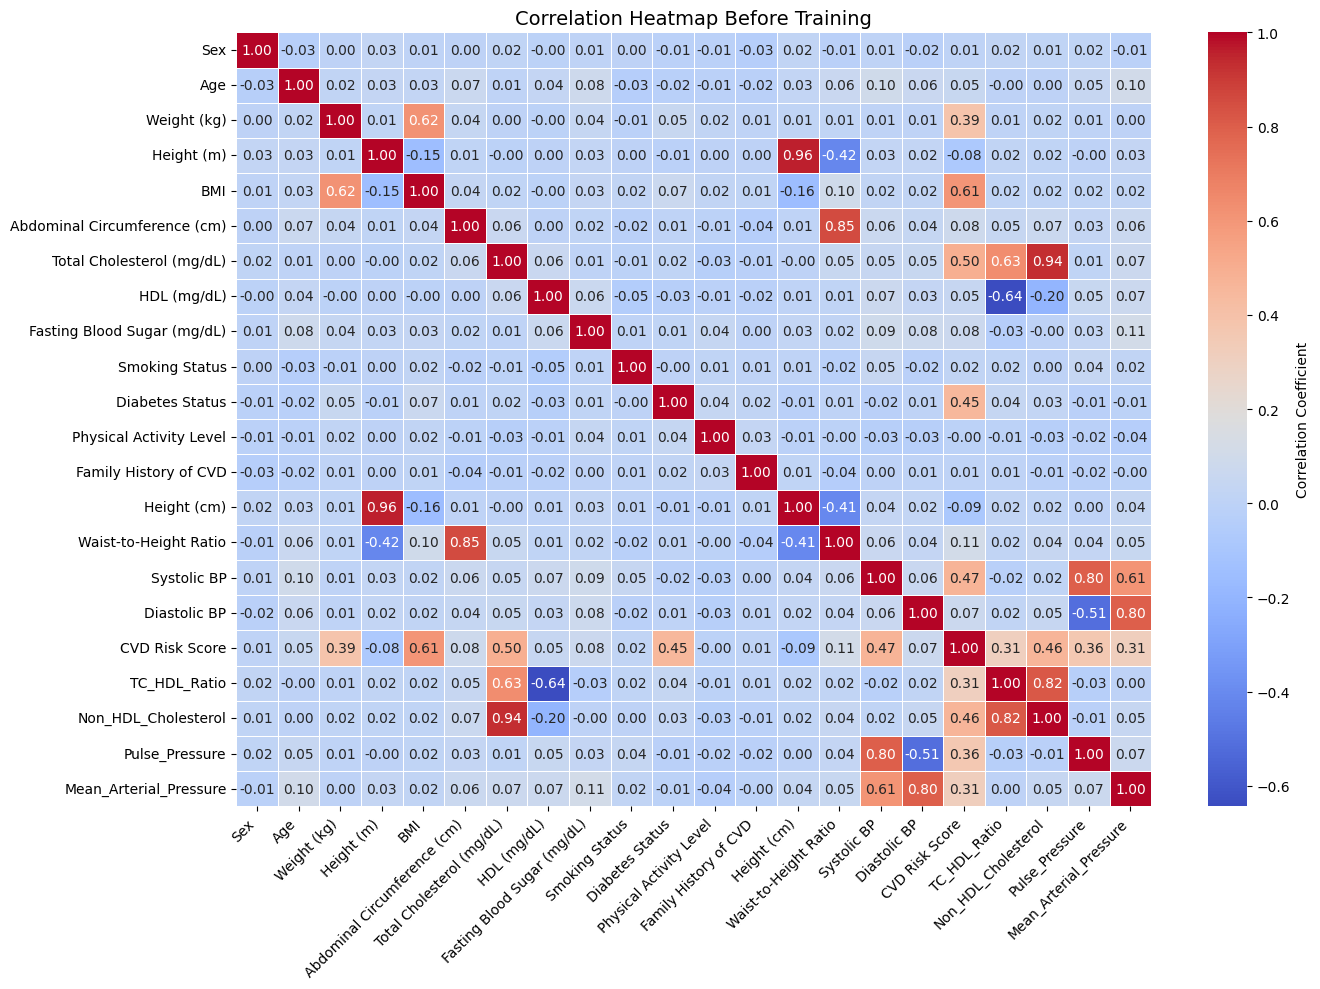

In [ ]:
# Create an EDA copy for correlation only
df_eda = df_model.copy()

# Keep only numeric columns
df_eda = df_eda.select_dtypes(include=[np.number])

# Fill missing numeric values with median ONLY for correlation visualization
df_eda = df_eda.fillna(df_eda.median(numeric_only=True))

# Compute correlation matrix
corr_matrix = df_eda.corr()

# Plot heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=False,
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title("Correlation Heatmap Before Training", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
X = df_model.drop(columns=[TARGET_COL])
y = df_model[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

X_train shape: (1167, 23)
X_test shape : (292, 23)


In [ ]:
# Identify column types from training data only
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

Numeric features: ['Sex', 'Age', 'Weight (kg)', 'Height (m)', 'BMI', 'Abdominal Circumference (cm)', 'Total Cholesterol (mg/dL)', 'HDL (mg/dL)', 'Fasting Blood Sugar (mg/dL)', 'Smoking Status', 'Diabetes Status', 'Physical Activity Level', 'Family History of CVD', 'Height (cm)', 'Waist-to-Height Ratio', 'Systolic BP', 'Diastolic BP', 'TC_HDL_Ratio', 'Non_HDL_Cholesterol', 'Pulse_Pressure', 'Mean_Arterial_Pressure']

Categorical features: ['Blood Pressure (mmHg)', 'Blood Pressure Category']


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Tuned Ridge pipeline
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

# Search space for alpha
ridge_param_grid = {
    "model__alpha": np.logspace(-4, 4, 20)
}

# Grid search
ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=0
)

# Fit tuned Ridge
ridge_grid.fit(X_train, y_train)

# Final tuned Ridge pipeline
best_ridge_pipeline = ridge_grid.best_estimator_

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])
print("Best CV RMSE:", -ridge_grid.best_score_)

# Test set evaluation
y_pred_ridge_tuned = best_ridge_pipeline.predict(X_test)

ridge_tuned_results = {
    "Model": "Ridge (Tuned)",
    "Test_MSE": mean_squared_error(y_test, y_pred_ridge_tuned),
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned)),
    "Test_MAE": mean_absolute_error(y_test, y_pred_ridge_tuned),
    "Test_R2": r2_score(y_test, y_pred_ridge_tuned)
}

ridge_tuned_results_df = pd.DataFrame([ridge_tuned_results])
display(ridge_tuned_results_df)

Best Ridge alpha: 4.281332398719396
Best CV RMSE: 0.4299700936209643


,Model,Test_MSE,Test_RMSE,Test_MAE,Test_R2
0,Ridge (Tuned),0.173932,0.417051,0.181385,0.971158


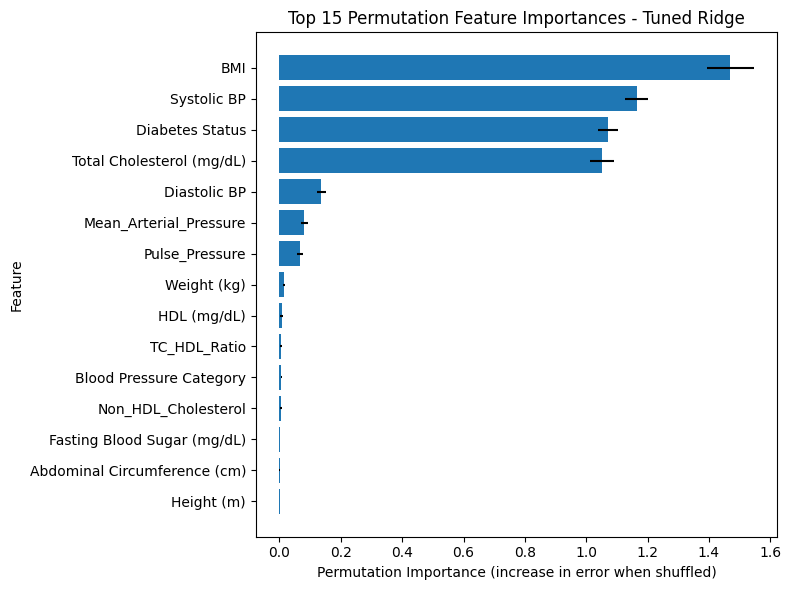

In [ ]:
top_n = 15
plot_df = perm_importance_df.head(top_n).sort_values("Importance_Mean", ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_STD"]
)
plt.xlabel("Permutation Importance (increase in error when shuffled)")
plt.ylabel("Feature")
plt.title("Top 15 Permutation Feature Importances - Tuned Ridge")
plt.tight_layout()
plt.show()

In [ ]:
perm_importance_df["Stability_Ratio"] = (
    perm_importance_df["Importance_Mean"] / (perm_importance_df["Importance_STD"] + 1e-8)
)

stability_df = perm_importance_df.sort_values(
    ["Importance_Mean", "Stability_Ratio"],
    ascending=[False, False]
)

display(stability_df.head(20))

,Feature,Importance_Mean,Importance_STD,Stability_Ratio
4,BMI,1.469516,0.075921,19.355729
16,Systolic BP,1.164194,0.038778,30.022054
11,Diabetes Status,1.071658,0.031897,33.597693
7,Total Cholesterol (mg/dL),1.052415,0.039126,26.897791
17,Diastolic BP,0.136043,0.014761,9.216379
22,Mean_Arterial_Pressure,0.080732,0.012108,6.667769
21,Pulse_Pressure,0.067228,0.008834,7.610188
2,Weight (kg),0.014387,0.002337,6.154742
8,HDL (mg/dL),0.006798,0.003792,1.792586
19,TC_HDL_Ratio,0.005832,0.003007,1.939766


In [ ]:
models = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "CatBoost": CatBoostRegressor(
        iterations=400,
        learning_rate=0.03,
        depth=4,
        loss_function="RMSE",
        eval_metric="RMSE",
        random_seed=RANDOM_STATE,
        verbose=0
    )
}

In [ ]:
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

print("Pipelines created:", list(pipelines.keys()))

Pipelines created: ['Extra Trees', 'XGBoost', 'CatBoost']


In [ ]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return mse, rmse, mae, r2

test_results = []
fitted_pipelines = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    mse, rmse, mae, r2 = regression_metrics(y_test, y_pred)

    test_results.append({
        "Model": name,
        "Test_MSE": mse,
        "Test_RMSE": rmse,
        "Test_MAE": mae,
        "Test_R2": r2
    })

    fitted_pipelines[name] = pipe

test_results_df = pd.DataFrame(test_results).sort_values("Test_RMSE").reset_index(drop=True)
display(test_results_df)

,Model,Test_MSE,Test_RMSE,Test_MAE,Test_R2
0,CatBoost,0.232678,0.482368,0.286363,0.961416
1,XGBoost,0.255681,0.505649,0.319128,0.957602
2,Extra Trees,0.337754,0.581166,0.403287,0.943992


In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe,
        X_train, y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False
    )

    cv_rows.append({
        "Model": name,
        "CV_RMSE_Mean": -scores["test_rmse"].mean(),
        "CV_RMSE_STD": scores["test_rmse"].std(),
        "CV_MAE_Mean": -scores["test_mae"].mean(),
        "CV_MAE_STD": scores["test_mae"].std(),
        "CV_R2_Mean": scores["test_r2"].mean(),
        "CV_R2_STD": scores["test_r2"].std()
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("CV_RMSE_Mean").reset_index(drop=True)
display(cv_results_df)

,Model,CV_RMSE_Mean,CV_RMSE_STD,CV_MAE_Mean,CV_MAE_STD,CV_R2_Mean,CV_R2_STD
0,CatBoost,0.491730,0.027030,0.290613,0.009960,0.958741,0.004842
1,XGBoost,0.516049,0.025161,0.335202,0.009960,0.954540,0.005021
2,Extra Trees,0.602927,0.024761,0.417174,0.019213,0.938062,0.005503


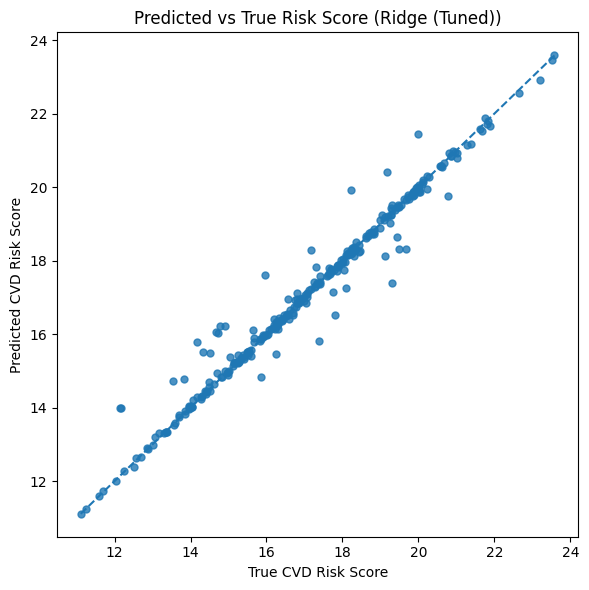

In [ ]:
best_model_name = "Ridge (Tuned)"
best_pipeline = best_ridge_pipeline
best_pred = best_pipeline.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, s=25, alpha=0.8)

mn = min(y_test.min(), best_pred.min())
mx = max(y_test.max(), best_pred.max())
plt.plot([mn, mx], [mn, mx], linestyle="--")

plt.xlabel("True CVD Risk Score")
plt.ylabel("Predicted CVD Risk Score")
plt.title(f"Predicted vs True Risk Score ({best_model_name})")
plt.tight_layout()
plt.show()

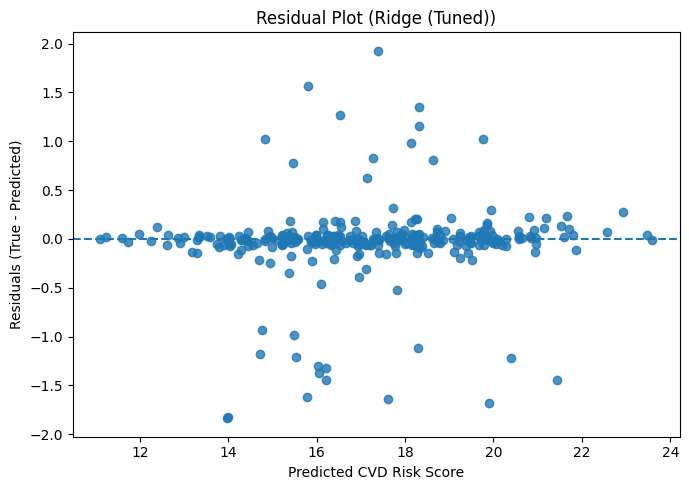

In [ ]:
residuals = y_test - best_pred

plt.figure(figsize=(7, 5))
plt.scatter(best_pred, residuals, alpha=0.8)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted CVD Risk Score")
plt.ylabel("Residuals (True - Predicted)")
plt.title(f"Residual Plot ({best_model_name})")
plt.tight_layout()
plt.show()

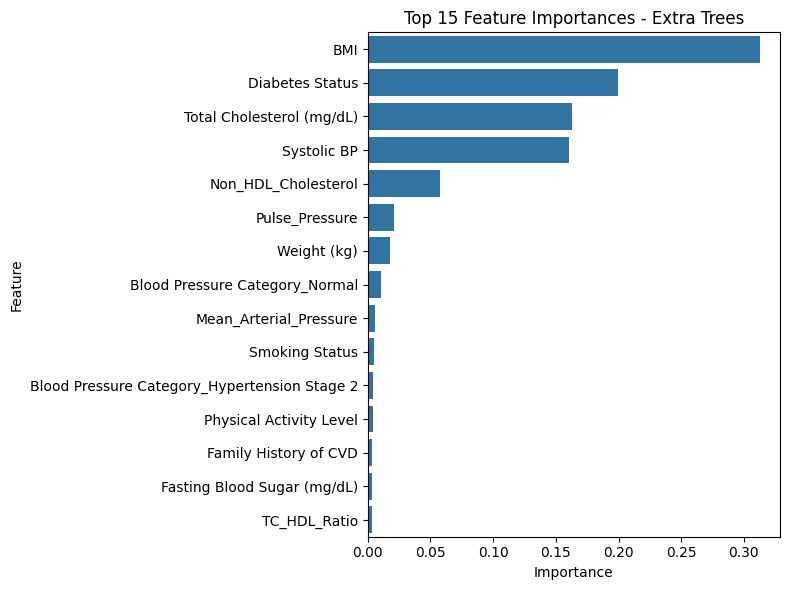

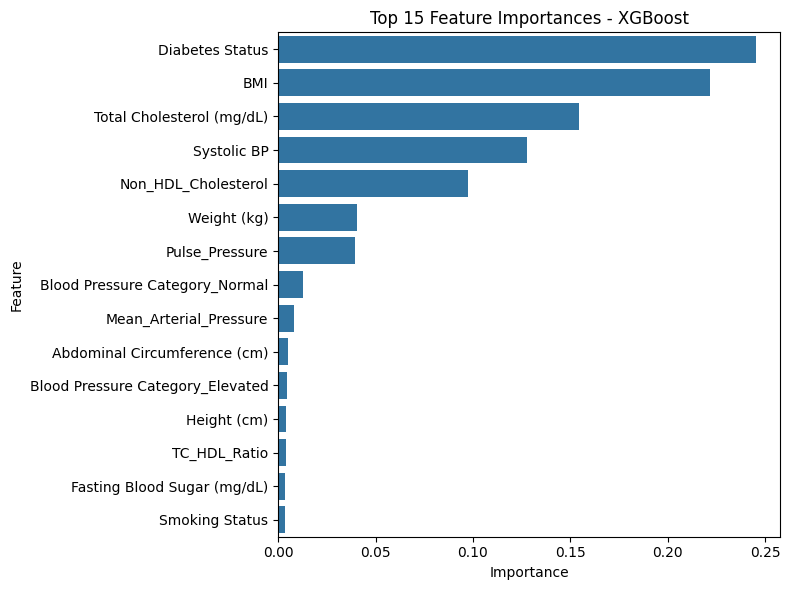

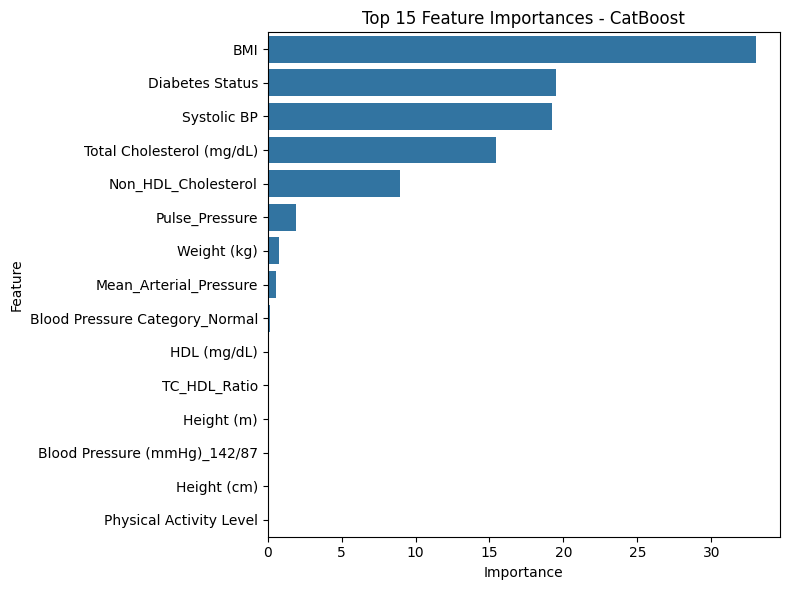

In [ ]:
def plot_tree_feature_importance(fitted_pipeline, model_name, top_n=15):
    model = fitted_pipeline.named_steps["model"]
    preprocessor = fitted_pipeline.named_steps["preprocessor"]

    if not hasattr(model, "feature_importances_"):
        print(f"{model_name} does not provide feature_importances_.")
        return

    feature_names = preprocessor.get_feature_names_out()
    feature_names = [f.split("__")[1] if "__" in f else f for f in feature_names]
    importances = model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(top_n)

    plt.figure(figsize=(8, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(f"Top {top_n} Feature Importances - {model_name}")
    plt.tight_layout()
    plt.show()

# Run for tree-based models
for model_name in ["Extra Trees", "XGBoost", "CatBoost"]:
    if model_name in fitted_pipelines:
        plot_tree_feature_importance(fitted_pipelines[model_name], model_name, top_n=15)

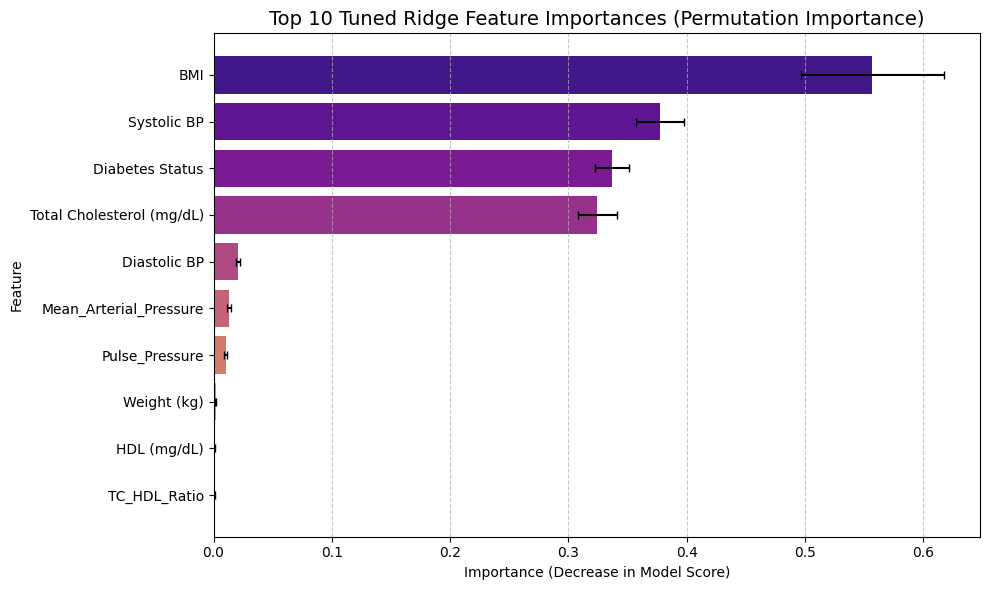

In [ ]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns

perm_importance = permutation_importance(
    best_ridge_pipeline, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(10), x='Importance', y='Feature', palette='plasma')
plt.errorbar(
    x=importance_df.head(10)['Importance'],
    y=range(10),
    xerr=importance_df.head(10)['Std'],
    fmt='none',
    c='black',
    capsize=3
)
plt.title('Top 10 Tuned Ridge Feature Importances (Permutation Importance)', fontsize=14)
plt.xlabel('Importance (Decrease in Model Score)')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
comparison_df = pd.DataFrame({"True": y_test.reset_index(drop=True)})

comparison_df["Ridge (Tuned)"] = best_ridge_pipeline.predict(X_test)

for name, pipe in fitted_pipelines.items():
    comparison_df[name] = pipe.predict(X_test)

display(comparison_df.head(10))

,True,Ridge (Tuned),Extra Trees,XGBoost,CatBoost
0,16.384,16.388756,16.786261,16.519716,16.482930
1,17.070,17.128190,17.415198,17.493052,17.193483
2,23.580,23.587542,22.753830,22.927092,23.352510
3,19.120,18.134713,18.249466,18.430508,17.914557
4,18.825,18.723214,18.392405,18.590157,18.748292
5,17.170,17.227679,17.400174,17.208454,17.274208
6,15.970,17.606959,17.466218,17.405823,17.539253
7,17.417,17.349798,17.589578,17.371147,17.292124
8,16.833,16.842511,16.894784,16.741278,16.673705
9,18.630,18.616896,17.233498,17.768742,18.243751


In [ ]:
import joblib

joblib.dump(best_ridge_pipeline, "best_cvd_regression_pipeline.pkl")
print("Saved best pipeline: Ridge (Tuned)")

Saved best pipeline: Ridge (Tuned)


In [ ]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso())
])

lasso_param_grid = {
    "model__alpha": np.logspace(-4, 4, 20)
}

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=0
)

lasso_grid.fit(X_train, y_train)

best_lasso_pipeline = lasso_grid.best_estimator_

print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"])
print("Best CV RMSE:", -lasso_grid.best_score_)

y_pred_lasso_tuned = best_lasso_pipeline.predict(X_test)

lasso_tuned_results = {
    "Model": "Lasso (Tuned)",
    "Test_MSE": mean_squared_error(y_test, y_pred_lasso_tuned),
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_pred_lasso_tuned)),
    "Test_MAE": mean_absolute_error(y_test, y_pred_lasso_tuned),
    "Test_R2": r2_score(y_test, y_pred_lasso_tuned)
}

lasso_tuned_results_df = pd.DataFrame([lasso_tuned_results])
display(lasso_tuned_results_df)

Best Lasso alpha: 0.012742749857031334
Best CV RMSE: 0.42312417956831244


,Model,Test_MSE,Test_RMSE,Test_MAE,Test_R2
0,Lasso (Tuned),0.178107,0.422027,0.169163,0.970466


In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

base_models = [
    ('lasso', Lasso(alpha=lasso_grid.best_params_['model__alpha'], max_iter=10000, random_state=RANDOM_STATE)),
    ('ridge', Ridge(alpha=ridge_grid.best_params_['model__alpha'], random_state=RANDOM_STATE)),
    ('rf', RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE)),
    ('svr', SVR(C=3.0, epsilon=0.05))
]

meta_model = LinearRegression()

stacking_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("stacking_model", StackingRegressor(
        estimators=base_models,
        final_estimator=meta_model,
        n_jobs=-1,
        passthrough=False
    ))
])

stacking_pipeline.fit(X_train, y_train)

y_pred_stacking = stacking_pipeline.predict(X_test)

stacking_results = {
    "Model": "Stacking",
    "Test_MSE": mean_squared_error(y_test, y_pred_stacking),
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_pred_stacking)),
    "Test_MAE": mean_absolute_error(y_test, y_pred_stacking),
    "Test_R2": r2_score(y_test, y_pred_stacking)
}

stacking_results_df = pd.DataFrame([stacking_results])
display(stacking_results_df)

,Model,Test_MSE,Test_RMSE,Test_MAE,Test_R2
0,Stacking,0.175257,0.418637,0.165699,0.970938


In [ ]:
from sklearn.model_selection import cross_val_score, KFold # Add cross_val_score here

lasso_cv_results = cross_val_score(
    best_lasso_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_cv_rmse_mean = -lasso_cv_results.mean()
lasso_cv_rmse_std = lasso_cv_results.std()

print("Lasso Cross-Validation RMSE Mean:", lasso_cv_rmse_mean)
print("Lasso Cross-Validation RMSE Std:", lasso_cv_rmse_std)

Lasso Cross-Validation RMSE Mean: 0.4305259159755307
Lasso Cross-Validation RMSE Std: 0.025682682915311606


In [ ]:
stacking_cv_results = cross_val_score(
    stacking_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

stacking_cv_rmse_mean = -stacking_cv_results.mean()
stacking_cv_rmse_std = stacking_cv_results.std()

print("Stacking Cross-Validation RMSE Mean:", stacking_cv_rmse_mean)
print("Stacking Cross-Validation RMSE Std:", stacking_cv_rmse_std)

Stacking Cross-Validation RMSE Mean: 0.4316653066906283
Stacking Cross-Validation RMSE Std: 0.023579504587444636


In [ ]:
scoring='neg_root_mean_squared_error'

In [ ]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd
import numpy as np

models = {
    "Ridge (Tuned)": best_ridge_pipeline,
    "Lasso (Tuned)": best_lasso_pipeline,
    "Stacking": stacking_pipeline,
    "CatBoost": fitted_pipelines["CatBoost"],
    "XGBoost": fitted_pipelines["XGBoost"],
    "Extra Trees": fitted_pipelines["Extra Trees"]
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []

for name, model in models.items():
    # Ensure fitted
    model.fit(X_train, y_train)

    # Test set evaluation
    y_pred = model.predict(X_test)

    test_mse = mean_squared_error(y_test, y_pred)
    test_rmse = np.sqrt(test_mse)
    test_mae = mean_absolute_error(y_test, y_pred)
    test_r2 = r2_score(y_test, y_pred)

    # Cross validation
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    cv_rmse = -cv_scores["test_rmse"]
    cv_mae = -cv_scores["test_mae"]
    cv_r2 = cv_scores["test_r2"]

    rows.append({
        "Model": name,
        "Test_MSE": test_mse,
        "Test_RMSE": test_rmse,
        "Test_MAE": test_mae,
        "Test_R2": test_r2,
        "CV_RMSE_Mean": cv_rmse.mean(),
        "CV_RMSE_STD": cv_rmse.std(),
        "CV_MAE_Mean": cv_mae.mean(),
        "CV_MAE_STD": cv_mae.std(),
        "CV_R2_Mean": cv_r2.mean(),
        "CV_R2_STD": cv_r2.std()
    })

final_results = pd.DataFrame(rows).round(4).sort_values("Test_RMSE").reset_index(drop=True)
display(final_results)

,Model,Test_MSE,Test_RMSE,Test_MAE,Test_R2,CV_RMSE_Mean,CV_RMSE_STD,CV_MAE_Mean,CV_MAE_STD,CV_R2_Mean,CV_R2_STD
0,Ridge (Tuned),0.1739,0.4171,0.1814,0.9712,0.4369,0.0184,0.1896,0.0062,0.9675,0.0032
1,Stacking,0.1753,0.4186,0.1657,0.9709,0.4317,0.0236,0.1660,0.0043,0.9682,0.0039
2,Lasso (Tuned),0.1781,0.4220,0.1692,0.9705,0.4305,0.0257,0.1663,0.0070,0.9683,0.0042
3,CatBoost,0.2327,0.4824,0.2864,0.9614,0.4917,0.0270,0.2906,0.0100,0.9587,0.0048
4,XGBoost,0.2557,0.5056,0.3191,0.9576,0.5160,0.0252,0.3352,0.0100,0.9545,0.0050
5,Extra Trees,0.3378,0.5812,0.4033,0.9440,0.6029,0.0248,0.4172,0.0192,0.9381,0.0055


In [ ]:
!pip -q install shap

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

shap.initjs()

In [ ]:
ridge_final_pipeline = best_ridge_pipeline
print(ridge_final_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Sex', 'Age', 'Weight (kg)',
                                                   'Height (m)', 'BMI',
                                                   'Abdominal Circumference '
                                                   '(cm)',
                                                   'Total Cholesterol (mg/dL)',
                                                   'HDL (mg/dL)',
                                                   'Fasting Blood Sugar '
                                                   '(mg/

In [ ]:
preprocessor_fitted = ridge_final_pipeline.named_steps["preprocessor"]
ridge_model_fitted = ridge_final_pipeline.named_steps["model"]

X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(X_test)

if sparse.issparse(X_train_transformed):
    X_train_transformed = X_train_transformed.toarray()

if sparse.issparse(X_test_transformed):
    X_test_transformed = X_test_transformed.toarray()

feature_names = preprocessor_fitted.get_feature_names_out()
feature_names = [f.split("__")[1] if "__" in f else f for f in feature_names]

X_train_df = pd.DataFrame(X_train_transformed, columns=feature_names)
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

print("Train shape:", X_train_df.shape)
print("Test shape :", X_test_df.shape)

Train shape: (1167, 1003)
Test shape : (292, 1003)


In [ ]:
explainer_ridge = shap.LinearExplainer(ridge_model_fitted, X_train_df)
shap_values_ridge = explainer_ridge.shap_values(X_test_df)

print("SHAP values shape:", np.array(shap_values_ridge).shape)

SHAP values shape: (292, 1003)


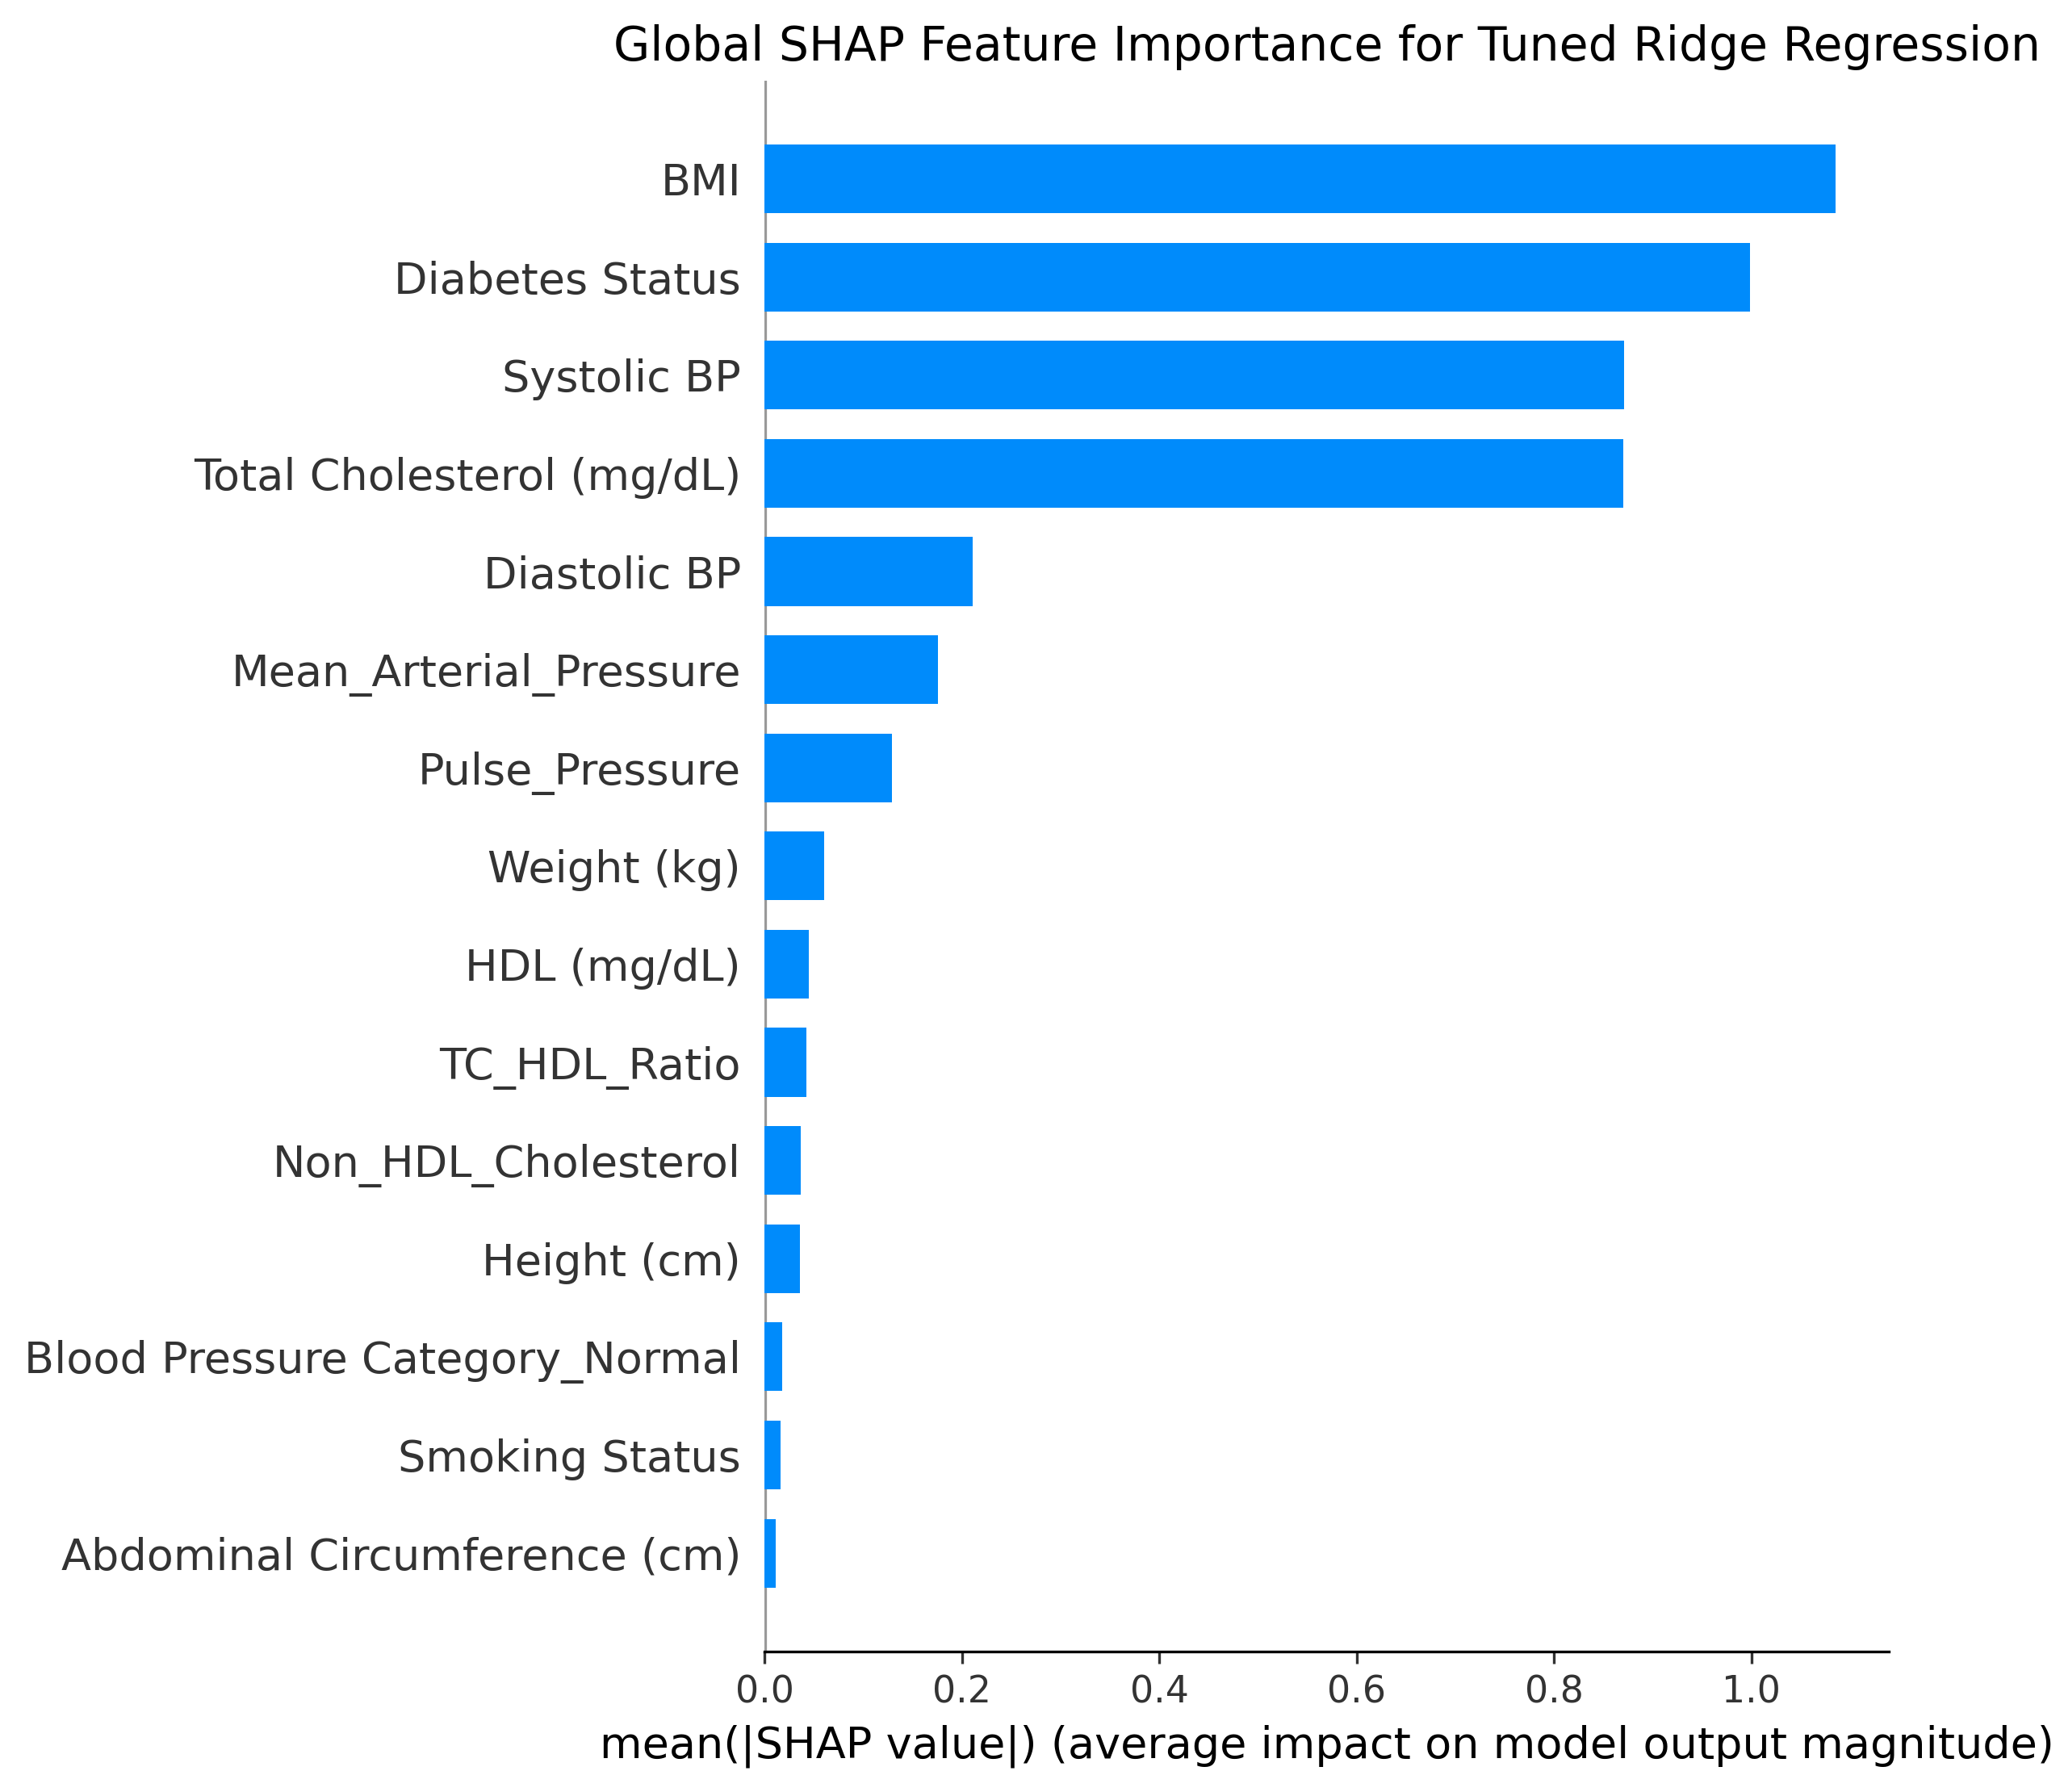

In [ ]:
plt.figure(figsize=(10, 6), dpi=300)
shap.summary_plot(
    shap_values_ridge,
    X_test_df,
    plot_type="bar",
    max_display=15,
    show=False
)
plt.title("Global SHAP Feature Importance for Tuned Ridge Regression", fontsize=14)
plt.tight_layout()
plt.show()

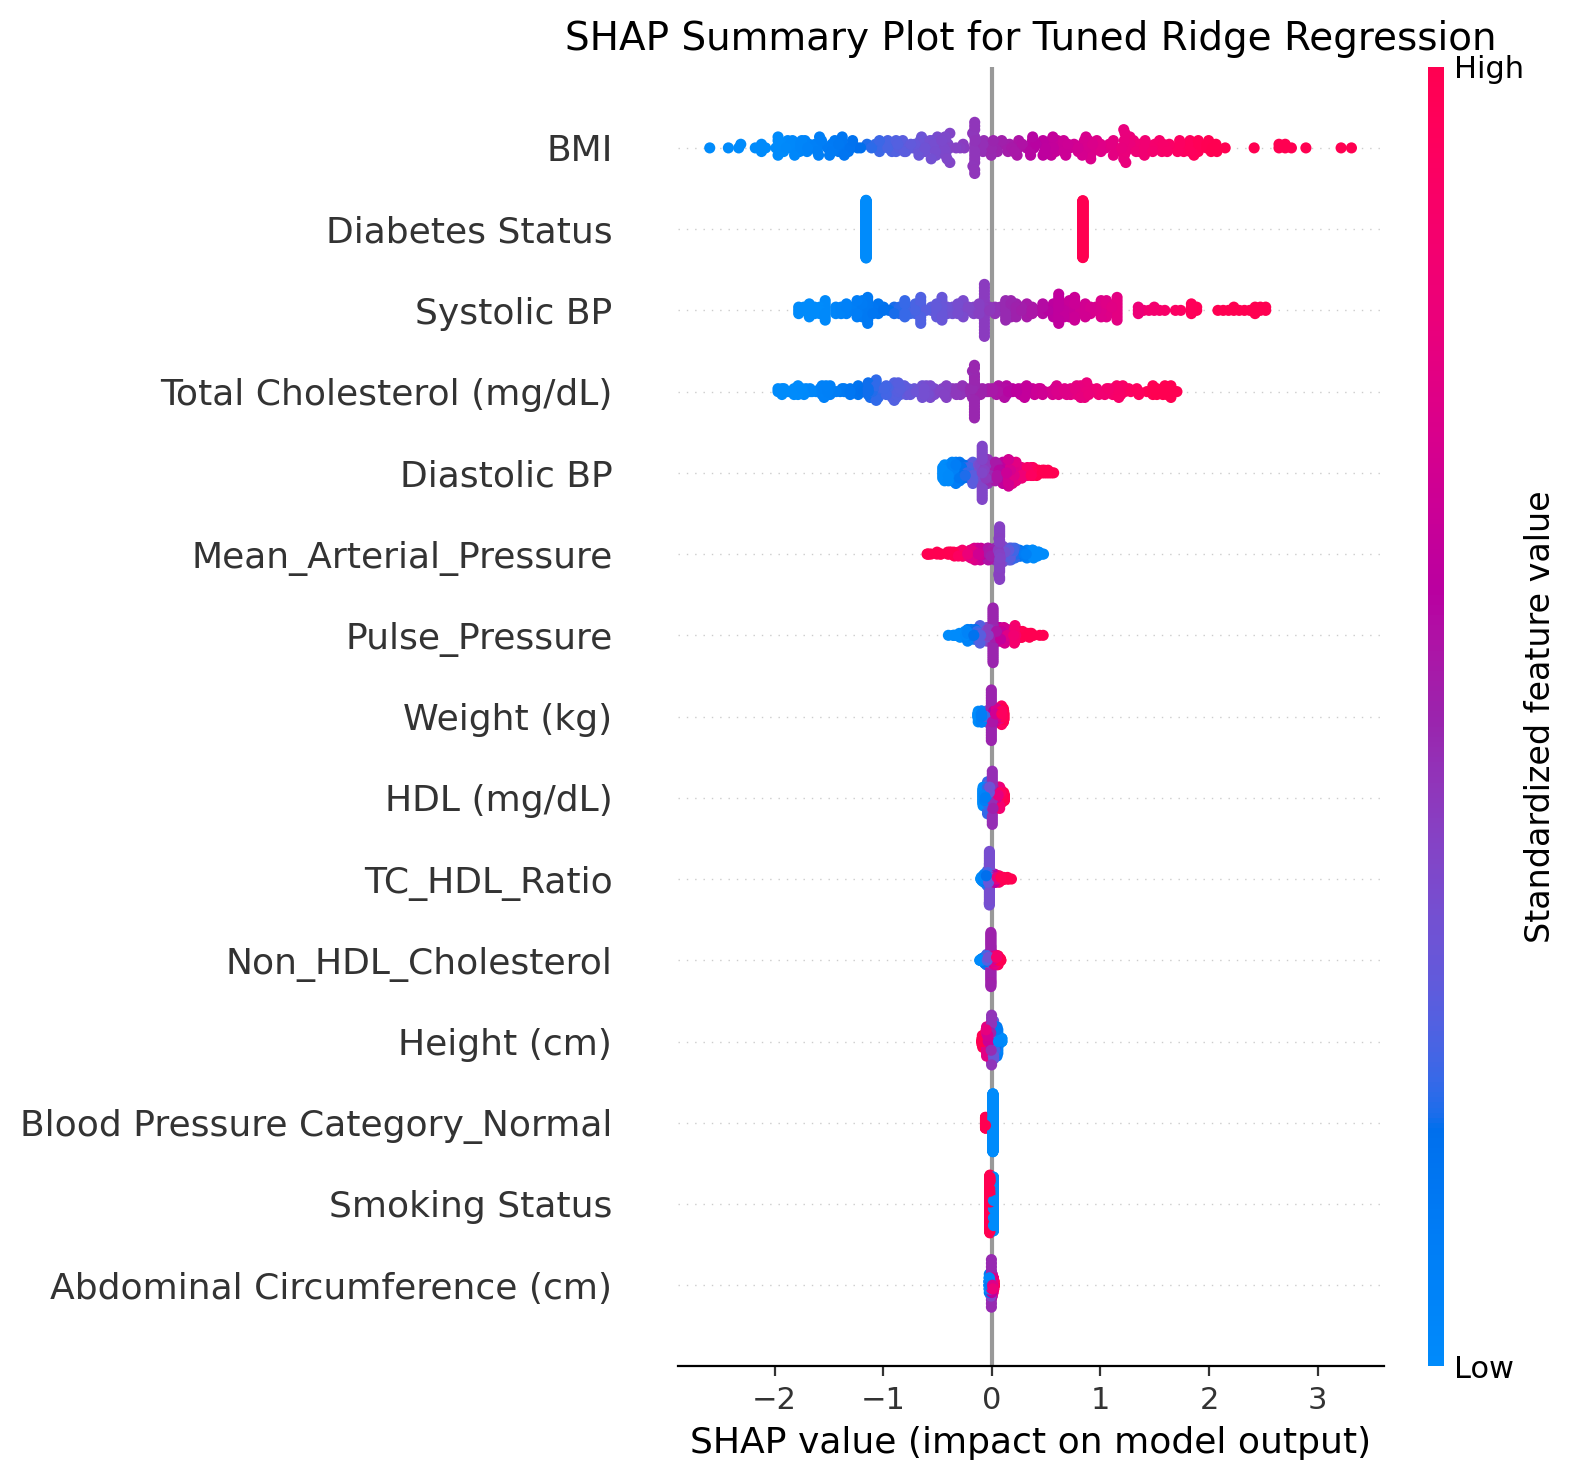

In [ ]:
plt.figure(figsize=(10, 6), dpi=200)
shap.summary_plot(
    shap_values_ridge,
    X_test_df,
    max_display=15,
    show=False
)

fig = plt.gcf()
axes = fig.axes
if len(axes) > 1:
    cbar_ax = axes[-1]
    cbar_ax.set_ylabel("Standardized feature value", fontsize=12)

plt.title("SHAP Summary Plot for Tuned Ridge Regression", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
mean_abs_shap = np.abs(shap_values_ridge).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values("Mean_Absolute_SHAP", ascending=False).reset_index(drop=True)

display(shap_importance_df.head(15))

,Feature,Mean_Absolute_SHAP
0,BMI,1.084951
1,Diabetes Status,0.998694
2,Systolic BP,0.870691
3,Total Cholesterol (mg/dL),0.870147
4,Diastolic BP,0.211203
5,Mean_Arterial_Pressure,0.175603
6,Pulse_Pressure,0.129350
7,Weight (kg),0.060365
8,HDL (mg/dL),0.044563
9,TC_HDL_Ratio,0.042314


Top 3 SHAP features: ['BMI', 'Diabetes Status', 'Systolic BP']


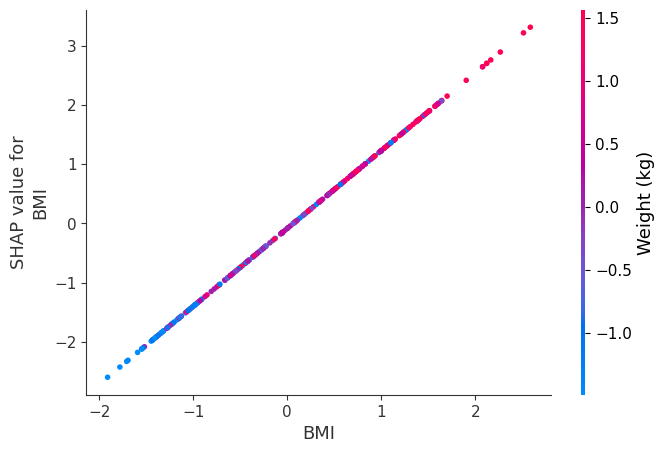

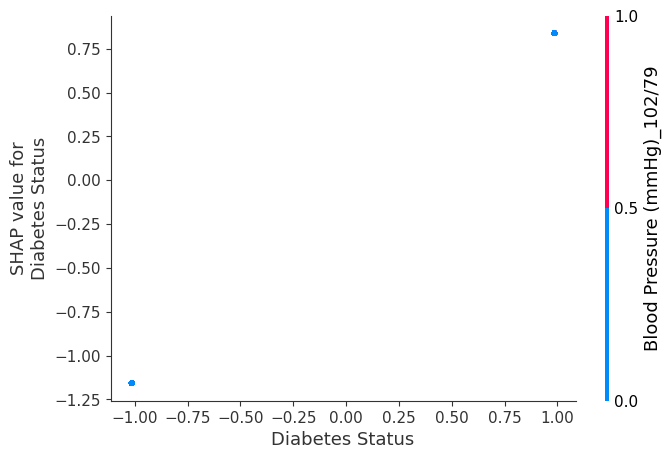

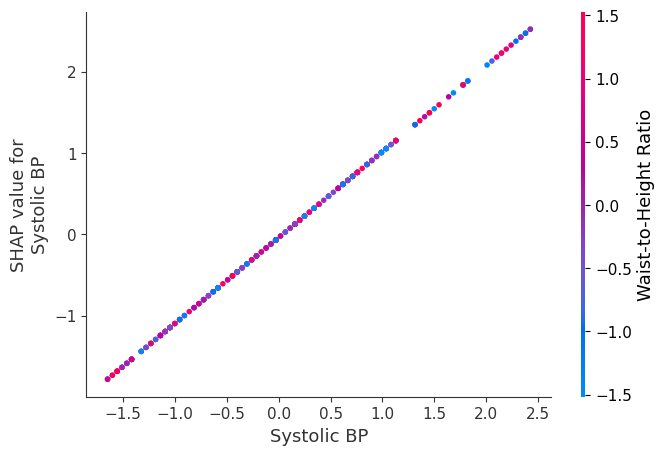

In [ ]:
top_features = shap_importance_df["Feature"].head(3).tolist()
print("Top 3 SHAP features:", top_features)

for feat in top_features:
    shap.dependence_plot(
        feat,
        shap_values_ridge,
        X_test_df,
        feature_names=feature_names,
        show=True
    )

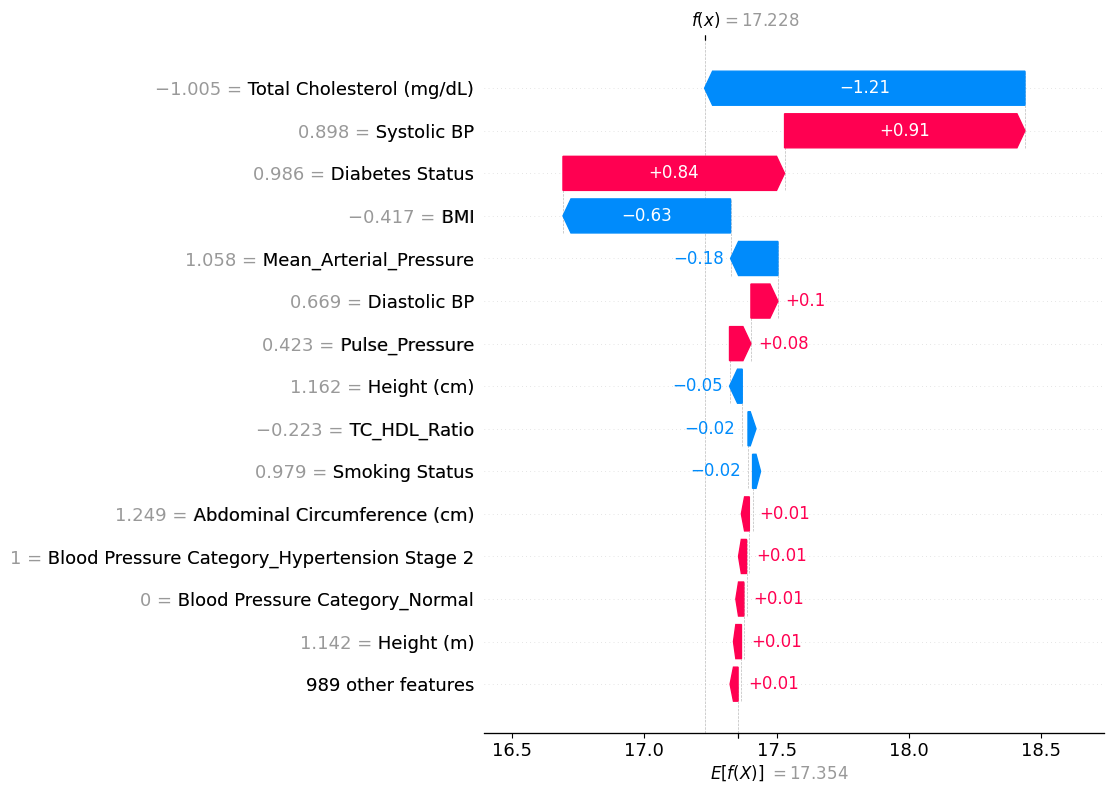

In [ ]:
sample_index = 5

shap_explanation = shap.Explanation(
    values=shap_values_ridge[sample_index],
    base_values=explainer_ridge.expected_value,
    data=X_test_df.iloc[sample_index],
    feature_names=feature_names
)

shap.plots.waterfall(shap_explanation, max_display=15)